# Trabalhos Práticos 2  - Classificação

Este documento é parte da segunda avaliação prática da disciplina de inteligência artificial ministrada em 2024/2025 na UFMT.

O tema do trabalho é o desenvolvimento de classificadores para identificação de vagas ocupadas e livres em imagens de estacionamentos.


**Esta é uma atividade individual. Escreva sua própria solução.**
---


#  Detecção de vagas ocupadas em um estacionamento


O tema dessa atividade é um sistema automatizado identifica vagas livres em estacionamentos usando imagens de câmeras fixas (indicadas pelas caixas amarelas na figura).

Como as câmeras e vagas permanecem na mesma posição, o sistema:

1. Mapeia previamente a localização de cada vaga nas imagens (Figuras abaixo)

2. Recorta individualmente cada área de vaga

3. Classifica cada recorte como "ocupado" ou "livre" usando um modelo de visão computacional (classificador).

O processo elimina a necessidade de sensores individuais, utilizando apenas as câmeras existentes.



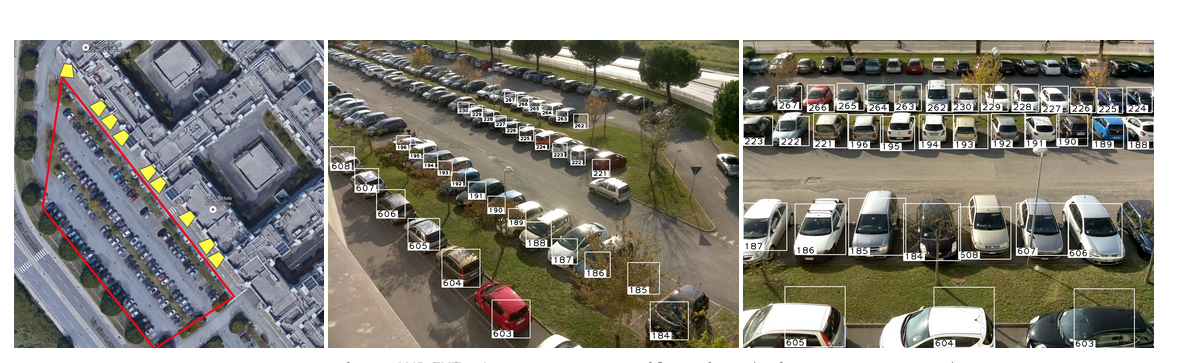

# Tarefas

Esse trabalho é dividido em duas tarefas:

1. **Desenvolvimento de modelos**: Desenvolva um modelo usando SVM, rede neural, CNN ou uma combinação desses modelos para imagens da base CNRPark.

2. **Análise e Experimentos**:  formule uma pergunta mensurável sobre seu sistema e desenhe um experimento para respondê-la.


Para analisar o modelo em diferentes situações climáticas você pode utilizar um subconjunto da base de dados CNRPark-EXT disponível [aqui](https://drive.google.com/file/d/1tPjq3GbifUxmppdDfmPiiJMRZ-jYiDMU/view?usp=sharing).


A nota do trabalho é a soma da pontuação das duas tarefas.
A pontuação de cada tarefa é indicada na Tabela 1.

| Tarefa                                   | Pontuação      |
| -----------------------------------------| -------------- |
| 1. Desenvolmento de um modelo para outros cenários             | **5.0 pontos** |
| 2. Análise e Experimentos                | **5.0 pontos** |
|**Total**                                 |**10.0 pontos** |



No item ''Análise e Experimentos'', você deve escolher algum aspecto do sistema para analisar. Esse processo consiste em definir uma pergunta específica sobre o comportamento ou eficiência do sistema e um experimento controlado para respondê-la.

Escolha uma pergunta sobre algo que te deixou curioso. Por exemplo,

- *Como o número de camadas ocultas em uma MLP afeta sua acurácia na classificação?*

- *Uma CNN padrão (Alexnet, Resnet) pode classificar as vagas em outros cenários com mais de 90% de acurácia usando transfer learning*?

- *Uma CNN padrão pré-treinada (Alexnet, Resnet) combinada com SVM (CNN extrai características para o SVM) pode classificar as vagas com mais 90% de acurácia?*



# Download dos Dados

Nesse trabalho, utilizaremos as imagens da base de dados [CNRPark]( http://cnrpark.it/), composto por 12 mil imagens coletadas em diferentes dias em julho de 2025 usando 2 câmeras.

As imagens foram coletadas em um ambiente contrado (dia ensolarado, boas condições de iluminação).

E estão organizadas da seguinte forma:


```
<CAMERA>/<CLASS>/YYYYMMDD_HHMM_<SLOT_ID>.jpg,
```
em que:

    `<CAMERA>` pode ser A ou B,
    `<CLASS>` pode ser  free (livre) or busy (ocupada),
    `YYYYMMDD_HHMM` é a data é horário de captura,
    `<SLOT_ID>` é o identificador da vaga para a particular camera



Assim, por exemplo, as imagem `A/busy/20150703_1425_32.jpg` é uma imagem capturada no dia 03 do julho de uma vaga com identificador 32 que está ocupada.

**Importante: Baixe os dados da atividade 3 no seguinte endereço**: [https://drive.google.com/file/d/1tPjq3GbifUxmppdDfmPiiJMRZ-jYiDMU/view?usp=sharing](https://drive.google.com/file/d/1tPjq3GbifUxmppdDfmPiiJMRZ-jYiDMU/view?usp=sharing)

In [ ]:
!gdown https://github.com/fabiocarrara/deep-parking/releases/download/archive/CNRPark-Patches-150x150.zip
!mkdir data
!unzip CNRPark-Patches-150x150.zip -d data/


A saída de streaming foi truncada nas últimas 5000 linhas.
  inflating: data/B/busy/20150708_0855_1.jpg  
  inflating: data/B/busy/20150708_1620_25.jpg  
  inflating: data/B/busy/20150708_1240_21.jpg  
  inflating: data/B/busy/20150708_0950_48.jpg  
  inflating: data/B/busy/20150708_1705_4.jpg  
  inflating: data/B/busy/20150708_1400_21.jpg  
  inflating: data/B/busy/20150708_1300_14.jpg  
  inflating: data/B/busy/20150708_1625_11.jpg  
  inflating: data/B/busy/20150708_1505_50.jpg  
  inflating: data/B/busy/20150708_1720_15.jpg  
  inflating: data/B/busy/20150708_1640_45.jpg  
  inflating: data/B/busy/20150708_1105_42.jpg  
  inflating: data/B/busy/20150708_1150_35.jpg  
  inflating: data/B/busy/20150708_1230_53.jpg  
  inflating: data/B/busy/20150708_1255_38.jpg  
  inflating: data/B/busy/20150708_1140_3.jpg  
  inflating: data/B/busy/20150708_1140_31.jpg  
  inflating: data/B/busy/20150708_1040_22.jpg  
  inflating: data/B/busy/20150708_1140_6.jpg  
  inflating: data/B/busy/20150708

# Implementação inicial


O código abaixo é uma implementação de uma rede neural com três camadas (modelos das aulas 9 e 10) para a classificação de vagas, com 512 unidades na camada intermediária e 1 uma unidade na camada de saída.  


Carregue os pacotes

In [ ]:
import os
import random
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt


# Manipulação do Dataset

O código abaixo combina as imagens das duas câmeras e divide as imagens em conjuntos de treinamento, validação e teste.

O ponto importante é que:

**Todas as imagens de uma vaga com um determinado id deve ficar no mesmo conjunto.**  

Por exemplo, se uma imagem da vaga 32 está foi incluída no conjunto de teste, todas as outras também precisam ser incluídas. Nem uma imagem dessa vaga pode estar no conjunto de testes

O objetivo disso é evitar  viéses, pois não queremos que o modelo decore.  

In [ ]:
# Configurações
RANDOM_SEED = 42
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001
IMG_SIZE = (64, 64)  # Redimensionar as imagens para este tamanho
CAMERA_TO_USE = 'A'  # Usar apenas imagens desta câmera

# Definir a semente para reprodutibilidade
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Verificar se GPU está disponível
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo de treinamento: {device}")

class CombinedParkingDataset(Dataset):
    def __init__(self, data_root, transform=None, split='train', split_ratio=(0.7, 0.15, 0.15)):
        """
        Args:
            data_root (str): Caminho para a pasta raiz dos dados
            transform (callable, optional): Transformações a serem aplicadas nas imagens
            split (str): Divisão a ser usada ('train', 'val', 'test')
            split_ratio (tuple): Proporção para train/val/test
        """
        self.data_root = data_root
        self.transform = transform
        self.split = split

        # Coletar todos os slots únicos de ambas as câmeras
        cameras = ['A', 'B']
        classes = ['free', 'busy']

        # Estrutura para armazenar os slots e seus arquivos
        slot_files = {}

        for camera in cameras:
            for class_name in classes:
                class_path = os.path.join(data_root, camera, class_name)
                if not os.path.exists(class_path):
                    continue

                for file_name in os.listdir(class_path):
                    if file_name.endswith('.jpg'):
                        # Extrair o slot_id do nome do arquivo
                        slot_id = f"{camera}_{file_name.split('_')[-1].replace('.jpg', '')}"
                        if slot_id not in slot_files:
                            slot_files[slot_id] = []
                        slot_files[slot_id].append((os.path.join(class_path, file_name), class_name))

        # Separar os slots em train, val, test
        slot_ids = list(slot_files.keys())
        random.shuffle(slot_ids)

        train_end = int(len(slot_ids) * split_ratio[0])
        val_end = train_end + int(len(slot_ids) * split_ratio[1])

        train_slots = slot_ids[:train_end]
        val_slots = slot_ids[train_end:val_end]
        test_slots = slot_ids[val_end:]

        # Selecionar os slots para a divisão atual
        if split == 'train':
            selected_slots = train_slots
        elif split == 'val':
            selected_slots = val_slots
        else:
            selected_slots = test_slots

        # Coletar todos os arquivos dos slots selecionados
        self.file_paths = []
        self.labels = []

        for slot in selected_slots:
            for file_path, class_name in slot_files[slot]:
                self.file_paths.append(file_path)
                self.labels.append(0 if class_name == 'free' else 1)  # 0 para free, 1 para busy

        print(f"{split}: {len(self.file_paths)} imagens de {len(selected_slots)} slots (combinação de câmeras A e B)")

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        label = self.labels[idx]

        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

    # Transformações (mantidas as mesmas)
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize(IMG_SIZE),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

# Criar datasets combinados
data_root = 'data/'  # Atualize com o caminho correto
train_dataset = CombinedParkingDataset(data_root, data_transforms['train'], 'train')
val_dataset = CombinedParkingDataset(data_root, data_transforms['val'], 'val')
test_dataset = CombinedParkingDataset(data_root, data_transforms['test'], 'test')

# Criar dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)


Dispositivo de treinamento: cpu
train: 8712 imagens de 72 slots (combinação de câmeras A e B)
val: 1815 imagens de 15 slots (combinação de câmeras A e B)
test: 2057 imagens de 17 slots (combinação de câmeras A e B)


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


# Sua Solução

Crie seus modelos utilizando SVM, redes neurais ou CNNs. Você pode utilizar transferência de aprendizagem.